Epoch: 1
Epoch: 2
Epoch: 3
Epoch: 4
Epoch: 5
Epoch: 6
Epoch: 7
Epoch: 8
Epoch: 9
Epoch: 10


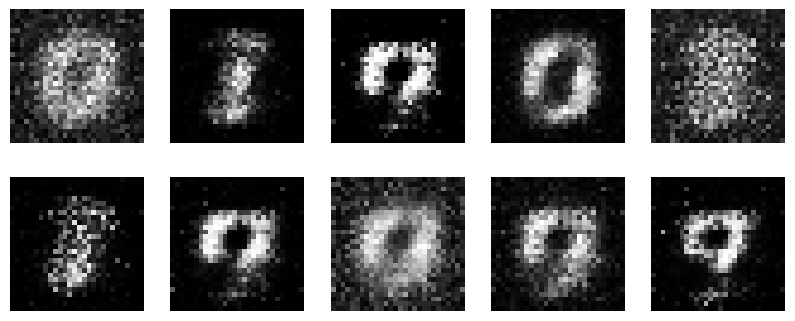

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers

# Load MNIST dataset
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 784).astype('float32') / 127.5 - 1

# Create Generator
generator = tf.keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(100,)),
    layers.Dense(784, activation='tanh')
])

# Create Discriminator
discriminator = tf.keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(784,)),
    layers.Dense(1, activation='sigmoid')
])

# Compile Discriminator
discriminator.compile(optimizer='adam',
                      loss='binary_crossentropy',
                      metrics=['accuracy'])

# Create GAN
discriminator.trainable = False

gan = tf.keras.Sequential([generator, discriminator])
gan.compile(optimizer='adam', loss='binary_crossentropy')

# Train GAN
for epoch in range(10):
    for i in range(0, len(x_train), 256):

        real = x_train[i:i+256]
        size = len(real)

        noise = np.random.normal(0, 1, (size, 100))
        fake = generator.predict(noise, verbose=0)

        # Train Discriminator
        discriminator.trainable = True
        discriminator.train_on_batch(real, np.ones((size, 1)))
        discriminator.train_on_batch(fake, np.zeros((size, 1)))

        # Train Generator
        discriminator.trainable = False
        gan.train_on_batch(noise, np.ones((size, 1)))

    print("Epoch:", epoch + 1)

# Generate images
noise = np.random.normal(0, 1, (10, 100))
images = generator.predict(noise, verbose=0)

# Display images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(images[i].reshape(28, 28), cmap='gray')
    plt.axis('off')

plt.show()